In [40]:
!pip install graphviz
import os
import sys

# Menambahkan path Graphviz secara langsung agar Python tidak bingung
graphviz_path = r'C:\Program Files\Graphviz\bin' 
os.environ["PATH"] += os.pathsep + graphviz_path

# Cek apakah folder tersebut benar-benar ada
if not os.path.exists(graphviz_path):
    print("Peringatan: Folder Graphviz tidak ditemukan! Periksa lokasi instalasi Anda.")
else:
    print("Path Graphviz berhasil dikonfigurasi!")

Peringatan: Folder Graphviz tidak ditemukan! Periksa lokasi instalasi Anda.



[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output
from graphviz import Digraph

In [36]:
class TreeNode:
    def __init__(self, key):
        self.key = key
        self.parent = None
        self.left = None
        self.right = None
        self.pos = [0, 0]
        self.col = "black"
        self.student_data = None 

    def spos(self):
        return str(self.pos[0]) + "," + str(self.pos[1]) + "!"

    def to_string(self):
        return str(self.key)

    def print(self):
        print("TreeNode: %d" % (self.key))

n10 = TreeNode(10)
n5 = TreeNode(5)
n14 = TreeNode(14)
n3 = TreeNode(3)

n5.parent = n10; n14.parent = n10
n10.left = n5 # left child
n10.right = n14 # right child
print([n10.to_string(), n10.left.to_string(), n10.right.to_string()])


['10', '5', '14']


In [37]:
class BST():
    def __init__(self):
        self.root = None
        self.list = []

    def insert(self, k):
        newNode = TreeNode(k)
        if self.root == None:
            self.root = newNode
        else:
            x = self.root
            p = None
            while x != None:
                p = x
                if newNode.key < x.key:
                    x = x.left
                else:
                    x = x.right
            newNode.parent = p
            if newNode.key < p.key:
                p.left = newNode
            else:
                p.right = newNode

    def insert_keys(self, keys):
        for k in keys:
            self.insert(k)
            
    def search(self, x, k):
        if x == None or x.key == k:
            if x: x.col = "green"
            return x
        if k < x.key:
            return self.search(x.left, k)
        return self.search(x.right, k)

    def find(self, k):
        return self.search(self.root, k)

    def transplant(self, u, v):
        if u.parent == None:
            self.root = v
        elif u == u.parent.left:
            u.parent.left = v
        else:
            u.parent.right = v
        if v != None:
            v.parent = u.parent

    def tree_minimum(self, x):
        while x.left != None:
            x = x.left
        return x

    def delete(self, k):
        z = self.find(k)
        if z == None: return
        if z.left == None:
            self.transplant(z, z.right)
        elif z.right == None:
            self.transplant(z, z.left)
        else:
            y = self.tree_minimum(z.right)
            if y.parent != z:
                self.transplant(y, y.right)
                y.right = z.right
                y.right.parent = y
            self.transplant(z, y)
            y.left = z.left
            y.left.parent = y

    def height(self, x):
        if x == None: return 0
        return 1 + int(np.maximum(self.height(x.left), self.height(x.right)))

    def inorder_traversal(self, x):
        if x != None:
            if x == self.root: self.list = []
            self.inorder_traversal(x.left)
            self.list.append(str(x.key))
            self.inorder_traversal(x.right)

    def postorder_traversal(self, x):
        if (x != None):
            if (x == self.root):
                self.list = []
            self.postorder_traversal(x.left)
            self.postorder_traversal(x.right)
            self.list.append(x.to_string())

    def rotate_left(self, x):

        y = x.right # set y to be right child
        if y != None:
            x.right = y.left # turn y's left subtree to x's right subtree
        if y.left != None:
            y.left.parent = x
        y.parent = x.parent
        if x.parent == None: # Case 1: x is root
            self.root = y
        elif x == x.parent.left:
            x.parent.left = y
        else:
            x.parent.right = y
        y.left = x
        x.parent = y

    def rotate_right(self, x):

        y = x.left
        x.left = y.right
        if y != None:
            x.right = y.left
        if y.right != None:
            y.right.parent = x
        y.parent = x.parent
        if x.parent == None:
            self.root = y
        elif x == x.parent.right:
            x.parent.right = y
        else:
            x.parent.left = y
        y.left = x
        x.parent = y 

In [38]:
class BSTViz:
    def __init__(self, bst):
        self.bst = bst

    def visualize(self):
        """Memvisualisasikan tree menggunakan graphviz"""
        if not self.bst.root:
            print("Pohon kosong")
            return
            
        tree = self.bst.root
        dot = Digraph()
        dot.engine = 'neato'
        h = self.bst.height(tree)
        tree.pos = [0, h]        
        dot.node(name=str(id(tree)), label=str(tree.key), color=tree.col, 
                 shape="circle", fixedsize="True", width="0.4", pos=tree.spos())

        def add_nodes(node, dot_obj):
            h_node = self.bst.height(node)
            
            # Logika untuk Anak Kiri [cite: 225-234]
            if node.left:
                # Hitung posisi relatif ke parent
                node.left.pos[0] = node.pos[0] - h_node/4
                node.left.pos[1] = node.pos[1] - 0.6
                dot_obj.node(name=str(id(node.left)), label=str(node.left.key), color=node.left.col,
                             shape="circle", fixedsize="True", width="0.4", pos=node.left.spos())
                dot_obj.edge(str(id(node)), str(id(node.left)))
                add_nodes(node.left, dot_obj) # Rekursif
                
            # Logika untuk Anak Kanan [cite: 235-244]
            if node.right:
                node.right.pos[0] = node.pos[0] + h_node/4
                node.right.pos[1] = node.pos[1] - 0.6
                dot_obj.node(name=str(id(node.right)), label=str(node.right.key), color=node.right.col,
                             shape="circle", fixedsize="True", width="0.4", pos=node.right.spos())
                dot_obj.edge(str(id(node)), str(id(node.right)))
                add_nodes(node.right, dot_obj) # Rekursif
                
            return dot_obj
        display(add_nodes(tree, dot))

In [39]:
class Student:
    def __init__(self, student_id, name):
        self.student_id = student_id
        self.name = name

    def __str__(self):
        return f"ID: {self.student_id}, Name: {self.name}"

    def __repr__(self):
        return self.__str__()

class BSTStudent(BST):
    def insert(self, student):
        new_node = TreeNode(student.student_id)
        new_node.student_data = student

        if self.root is None:
            self.root = new_node
        else:
            x = self.root
            p = None
            while x is not None:
                p = x
                if new_node.key < x.key:
                    x = x.left
                else:
                    x = x.right

            new_node.parent = p
            if new_node.key < p.key:
                p.left = new_node
            else:
                p.right = new_node

    def search(self, x, student_id):
        if x is None or x.key == student_id:
            if x: x.col = "green"
            return x
        if student_id < x.key:
            return self.search(x.left, student_id)
        else:
            # PERBAIKAN: Gunakan x.right, bukan self.root
            return self.search(x.right, student_id)

    def find(self, student_id):
        """Menambahkan fungsi find agar bisa dipanggil"""
        return self.search(self.root, student_id)

    def delete(self, student_id):
        z = self.find(student_id)
        if z is None:
            print(f"Student with ID {student_id} not found.")
            return
        super().delete(student_id)

# --- BAGIAN EKSEKUSI (Diletakkan di luar class/tanpa indentasi) ---

print("=== Implementasi BST untuk Data Siswa ===")

bst_students = BSTStudent()
print("Menyisipkan siswa...")
bst_students.insert(Student(10, "Budi")) 
bst_students.insert(Student(5, "Ani"))
bst_students.insert(Student(15, "Candra"))
bst_students.insert(Student(3, "Dewi"))
bst_students.insert(Student(7, "Eko"))
bst_students.insert(Student(12, "Fitri"))
bst_students.insert(Student(18, "Gita"))

print("BST setelah penyisipan:")
BSTViz(bst_students).visualize()

search_id = 7
print(f"\nMencari siswa dengan ID: {search_id}...")
found_node = bst_students.find(search_id)
if found_node and hasattr(found_node, 'student_data'):
    print(f"Ditemukan: {found_node.student_data}")
else:
    print(f"Siswa dengan ID {search_id} tidak ditemukan.")

search_id = 99
print(f"\nMencari siswa dengan ID: {search_id}...")
found_node = bst_students.find(search_id)
if found_node and hasattr(found_node, 'student_data'):
    print(f"Ditemukan: {found_node.student_data}")
else:
    print(f"Siswa dengan ID {search_id} tidak ditemukan.")

print("\nBST setelah pencarian:")
BSTViz(bst_students).visualize()

delete_id = 15
print(f"\nMenghapus siswa dengan ID: {delete_id}...")
bst_students.delete(delete_id)

print("BST setelah penghapusan:")
BSTViz(bst_students).visualize()

print("Daftar siswa setelah penghapusan (inorder traversal):")
bst_students.inorder_traversal(bst_students.root)
if bst_students.list:
    print([key for key in bst_students.list])
else:
    print("BST kosong.")

=== Implementasi BST untuk Data Siswa ===
Menyisipkan siswa...
BST setelah penyisipan:


ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH


Mencari siswa dengan ID: 7...
Ditemukan: ID: 7, Name: Eko

Mencari siswa dengan ID: 99...
Siswa dengan ID 99 tidak ditemukan.

BST setelah pencarian:


ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH


Menghapus siswa dengan ID: 15...
BST setelah penghapusan:


ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH

Daftar siswa setelah penghapusan (inorder traversal):
['3', '5', '7', '10', '12', '18']


Insert 10, 3, 5, 2, 12, 11


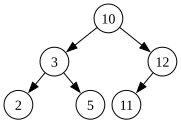

Found: 12


In [130]:
    bst = BST()
    print("Insert 10, 3, 5, 2, 12, 11")
    bst.insert_keys([10, 3, 5, 2, 12, 11])
    BSTViz(bst).visualize()
    node = bst.find(12)
    if node:
        print("Found: " + node.to_string())
    else:
        print("Node not found")

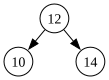

In [131]:
    bst = BST()
    bst.insert(12)
    bst.insert(10)
    bst.insert(14)
    BSTViz(bst).visualize()

Insert 10, 3, 5, 2, 12, 11
Delete 3:


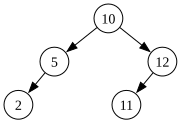

Height of the tree is 3


In [132]:
    bst = BST()
    print("Insert 10, 3, 5, 2, 12, 11")
    bst.insert_keys([10, 3, 5, 2, 12, 11])
    print("Delete 3:")
    bst.delete(3)
    BSTViz(bst).visualize()
    print("Height of the tree is %d" % bst.height(bst.root))

In [133]:
    bst = BST()
    print("Insert 10, 3, 5, 2, 12, 11")
    bst.insert_keys([10, 3, 5, 2, 12, 11])
    bst.inorder_traversal(bst.root)
    print(bst.list)
    bst.postorder_traversal(bst.root)
    print(bst.list)

Insert 10, 3, 5, 2, 12, 11
['2', '3', '5', '10', '11', '12']
['2', '5', '3', '11', '12', '10']


Insert 10, 12, 14


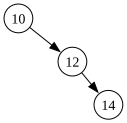

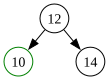

In [134]:
    bst = BST()
    print("Insert 10, 12, 14")
    bst.insert_keys([10, 12, 14])
    BSTViz(bst).visualize()
    n10 = bst.find(10)
    bst.rotate_left(n10)
    BSTViz(bst).visualize()

In [137]:
import ipywidgets as widgets
from ipywidgets import BoundedIntText, Button, HTML, Tab, HBox, VBox, Output, Layout
from numpy.random import seed, randint
from IPython.display import display, clear_output

# Inisialisasi Pohon (Pastikan class BST dan BSTViz sudah di-run sebelumnya)
tree = BST()

# Membuat Output widgets
out, out1, out2, out3 = Output(), Output(), Output(), Output()

# Setup Tab
tab = Tab(children = [out1, out2, out3],
          layout=Layout(width='100%', height='auto'))
tab.set_title(0, 'Binary search tree')
tab.set_title(1, 'AVL Tree')
tab.set_title(2, 'B-Tree')

# Kontrol Input
ui_key = BoundedIntText(value=20, min=0, max=100,
                        step=1, description='Enter Key:', disabled=False)

msg = "<p>Click on one of the buttons below!</p>"

# --- Tombol Insert ---
btn_insert = Button(description='Insert', button_style='success')
def on_button_insert_clicked(b):
    with out:
        clear_output()
        tree.insert(ui_key.value)
        BSTViz(tree).visualize()
btn_insert.on_click(on_button_insert_clicked)

# --- Tombol Delete ---
btn_delete = Button(description='Delete', button_style='primary')
def on_button_delete_clicked(b):
    with out:
        clear_output()
        tree.delete(ui_key.value)
        BSTViz(tree).visualize()
btn_delete.on_click(on_button_delete_clicked)

# --- Tombol Search ---
btn_search = Button(description='Search', button_style='info')
def on_button_search_clicked(b):
    with out:
        clear_output()
        print(f"Search: {ui_key.value}")
        foundnode = tree.find(ui_key.value)
        if (foundnode != None):
            print(f"Found: {ui_key.value} is in tree")
        else:
            print(f"Not found: {ui_key.value} not in tree")
        BSTViz(tree).visualize()
btn_search.on_click(on_button_search_clicked)

# --- Tombol Random ---
btn_rnd = Button(description='Random', button_style='warning')
def on_button_rnd_clicked(b):
    with out:
        clear_output()
        tree.root = None # Reset pohon
        seed() # Random seed baru tiap klik
        keys = randint(1, 50, 7)
        print(f"Generating random keys: {keys}")
        tree.insert_keys(keys)
        BSTViz(tree).visualize()
btn_rnd.on_click(on_button_rnd_clicked)

# --- Tombol Clear ---
btn_clear = Button(description='Clear', button_style='danger')
def on_button_clear_clicked(b):
    with out:
        clear_output()
        tree.root = None
        print("Tree cleared!")
btn_clear.on_click(on_button_clear_clicked)

# --- Layouting ---
layout_displ = Layout(height='400px', border='1px dotted blue', overflow ='auto')
layout_ctrl = Layout(height='auto')

with out1:
    htm = HTML(msg)
    msgbox = HTML("<p></p>")
    displ = HBox([out], layout=layout_displ)
    # Perbaikan layout_ctrl yang tadi terpotong
    ctrl = HBox([ui_key, btn_insert, btn_delete, btn_search, btn_rnd, btn_clear], layout=layout_ctrl)
    display(VBox([displ, htm, msgbox, ctrl]))

with out2:
    display(HTML("<h1>TODO</h1><p>Insert AVL Tree code here</p>"))

with out3:
    display(HTML("<h1>TODO</h1><p>Insert B-Tree code here</p>"))

# Tampilkan Tab Utama
display(tab)